In [ ]:
import pandas as pd
import os

In [ ]:
from google.colab import files

uploaded = files.upload()

Saving fact_inventory_daily.csv to fact_inventory_daily.csv


In [ ]:
df = pd.read_csv("fact_inventory_daily.csv")

df.head()

,date,store_id,sku_id,supplier_id,opening_stock,units_demanded,units_sold,closing_stock,reorder_point,reorder_placed,lead_time_days_expected,lead_time_days_actual,sales_velocity_7d,days_of_cover,is_festival_week,stockout_risk
0,2026-10-01,ST01,SKU001,SUP11,159.9,15,15.0,144.9,36.4,N,1,NaN,15.00,9.66,N,Safe
1,2026-10-02,ST01,SKU001,SUP11,144.9,10,10.0,134.9,36.4,N,1,NaN,12.50,10.79,N,Safe
2,2026-10-03,ST01,SKU001,SUP11,134.9,15,15.0,119.9,36.4,N,1,NaN,13.33,8.99,N,Safe
3,2026-10-04,ST01,SKU001,SUP11,119.9,10,10.0,109.9,36.4,N,1,NaN,12.50,8.79,N,Safe
4,2026-10-05,ST01,SKU001,SUP11,109.9,9,9.0,100.9,36.4,N,1,NaN,11.80,8.55,N,Safe


In [ ]:
print("Rows and Columns:", df.shape)
print("\nColumn Names:")
print(df.columns.tolist())

Rows and Columns: (21600, 16)

Column Names:
['date', 'store_id', 'sku_id', 'supplier_id', 'opening_stock', 'units_demanded', 'units_sold', 'closing_stock', 'reorder_point', 'reorder_placed', 'lead_time_days_expected', 'lead_time_days_actual', 'sales_velocity_7d', 'days_of_cover', 'is_festival_week', 'stockout_risk']


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 21600 entries, 0 to 21599
Data columns (total 16 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   date                     21600 non-null  object 
 1   store_id                 21600 non-null  object 
 2   sku_id                   21600 non-null  object 
 3   supplier_id              21600 non-null  object 
 4   opening_stock            21600 non-null  float64
 5   units_demanded           21600 non-null  int64  
 6   units_sold               21600 non-null  float64
 7   closing_stock            21600 non-null  float64
 8   reorder_point            21600 non-null  float64
 9   reorder_placed           21600 non-null  object 
 10  lead_time_days_expected  21600 non-null  int64  
 11  lead_time_days_actual    1701 non-null   float64
 12  sales_velocity_7d        21600 non-null  float64
 13  days_of_cover            21600 non-null  float64
 14  is_festival_week      

In [ ]:
# Check missing values
df.isnull().sum()

,0
date,0
store_id,0
sku_id,0
supplier_id,0
opening_stock,0
units_demanded,0
units_sold,0
closing_stock,0
reorder_point,0
reorder_placed,0


In [ ]:
# Check duplicate rows
df.duplicated().sum()

np.int64(0)

In [ ]:
df.dtypes

,0
date,object
store_id,object
sku_id,object
supplier_id,object
opening_stock,float64
units_demanded,int64
units_sold,float64
closing_stock,float64
reorder_point,float64
reorder_placed,object


In [ ]:
# Convert date column to datetime
df['date'] = pd.to_datetime(df['date'])

# Check data types again
df.dtypes

,0
date,datetime64[ns]
store_id,object
sku_id,object
supplier_id,object
opening_stock,float64
units_demanded,int64
units_sold,float64
closing_stock,float64
reorder_point,float64
reorder_placed,object


In [ ]:
# Basic statistical summary
df.describe()

,date,opening_stock,units_demanded,units_sold,closing_stock,reorder_point,lead_time_days_expected,lead_time_days_actual,sales_velocity_7d,days_of_cover
count,21600,21600.000000,21600.000000,21600.000000,21600.000000,21600.000000,21600.000000,1701.000000,21600.000000,21600.000000
mean,2026-10-15 12:00:00,127.246588,17.278380,16.753565,125.886069,72.349722,2.600000,3.373604,16.693251,8.137071
min,2026-10-01 00:00:00,0.000000,0.000000,0.000000,0.000000,3.000000,1.000000,1.000000,0.000000,0.000000
25%,2026-10-08 00:00:00,33.375000,5.750000,5.000000,32.800000,22.750000,1.000000,1.900000,5.570000,4.310000
50%,2026-10-15 12:00:00,75.200000,11.000000,11.000000,74.200000,47.050000,3.000000,3.200000,11.140000,7.540000
75%,2026-10-23 00:00:00,162.125000,23.000000,23.000000,160.000000,90.550000,4.000000,4.800000,23.000000,11.360000
max,2026-10-30 00:00:00,1091.600000,201.000000,201.000000,1091.600000,467.400000,5.000000,8.200000,117.570000,134.850000
std,NaN,146.969344,17.560305,17.255100,146.120852,76.896919,1.496698,1.724393,16.009877,5.153005


In [ ]:
# Count inventory risk levels
df['stockout_risk'].value_counts()

,count
stockout_risk,
Safe,14131
At-Risk,5186
Imminent,2283


In [ ]:
# Show At-Risk inventory items
at_risk = df[df['stockout_risk'] == 'At-Risk']

at_risk.head(20)

,date,store_id,sku_id,supplier_id,opening_stock,units_demanded,units_sold,closing_stock,reorder_point,reorder_placed,lead_time_days_expected,lead_time_days_actual,sales_velocity_7d,days_of_cover,is_festival_week,stockout_risk
9,2026-10-10,ST01,SKU001,SUP11,54.9,13,13.0,41.9,36.4,N,1,NaN,11.14,3.76,N,At-Risk
10,2026-10-11,ST01,SKU001,SUP11,41.9,16,16.0,25.9,36.4,Y,1,1.3,12.00,2.16,N,At-Risk
23,2026-10-24,ST01,SKU001,SUP11,52.8,18,18.0,34.8,36.4,Y,1,1.0,12.57,2.77,N,At-Risk
40,2026-10-11,ST02,SKU001,SUP11,5.8,2,2.0,3.8,4.0,Y,1,1.4,1.29,2.96,N,At-Risk
51,2026-10-22,ST02,SKU001,SUP11,7.4,3,3.0,4.4,4.0,N,1,NaN,1.43,3.06,N,At-Risk
56,2026-10-27,ST02,SKU001,SUP11,10.6,1,1.0,9.6,4.0,N,1,NaN,2.48,3.86,N,At-Risk
65,2026-10-06,ST03,SKU001,SUP11,56.2,16,16.0,40.2,33.9,N,1,NaN,11.83,3.40,N,At-Risk
67,2026-10-08,ST03,SKU001,SUP11,23.2,9,9.0,14.2,33.9,N,1,NaN,12.14,1.17,N,At-Risk
78,2026-10-19,ST03,SKU001,SUP11,58.6,16,16.0,42.6,33.9,N,1,NaN,11.57,3.68,N,At-Risk
79,2026-10-20,ST03,SKU001,SUP11,42.6,12,12.0,30.6,33.9,Y,1,1.0,11.57,2.64,N,At-Risk


In [ ]:
# Show important details for At-Risk items
at_risk[['date', 'store_id', 'sku_id', 'supplier_id',
         'closing_stock', 'reorder_point',
         'sales_velocity_7d', 'days_of_cover',
         'stockout_risk']].head(20)

,date,store_id,sku_id,supplier_id,closing_stock,reorder_point,sales_velocity_7d,days_of_cover,stockout_risk
9,2026-10-10,ST01,SKU001,SUP11,41.9,36.4,11.14,3.76,At-Risk
10,2026-10-11,ST01,SKU001,SUP11,25.9,36.4,12.00,2.16,At-Risk
23,2026-10-24,ST01,SKU001,SUP11,34.8,36.4,12.57,2.77,At-Risk
40,2026-10-11,ST02,SKU001,SUP11,3.8,4.0,1.29,2.96,At-Risk
51,2026-10-22,ST02,SKU001,SUP11,4.4,4.0,1.43,3.06,At-Risk
56,2026-10-27,ST02,SKU001,SUP11,9.6,4.0,2.48,3.86,At-Risk
65,2026-10-06,ST03,SKU001,SUP11,40.2,33.9,11.83,3.40,At-Risk
67,2026-10-08,ST03,SKU001,SUP11,14.2,33.9,12.14,1.17,At-Risk
78,2026-10-19,ST03,SKU001,SUP11,42.6,33.9,11.57,3.68,At-Risk
79,2026-10-20,ST03,SKU001,SUP11,30.6,33.9,11.57,2.64,At-Risk


In [ ]:
# Supplier-wise stockout risk analysis
supplier_risk = (
    df.groupby('supplier_id')['stockout_risk']
      .value_counts()
      .unstack(fill_value=0)
)

supplier_risk

stockout_risk,At-Risk,Imminent,Safe
supplier_id,,,
SUP01,502,38,540
SUP02,601,84,1115
SUP04,672,347,3301
SUP06,453,80,2347
SUP07,269,162,649
SUP08,277,193,970
SUP09,282,291,507
SUP10,218,133,369
SUP11,253,47,1140


In [ ]:
supplier_risk['risk_pct'] = (
    supplier_risk['At-Risk'] / supplier_risk.sum(axis=1) * 100
)

supplier_risk.sort_values('risk_pct', ascending=False)

stockout_risk,At-Risk,Imminent,Safe,risk_pct
supplier_id,,,,
SUP01,502,38,540,46.481481
SUP02,601,84,1115,33.388889
SUP14,464,125,851,32.222222
SUP15,229,156,335,31.805556
SUP10,218,133,369,30.277778
SUP13,404,43,993,28.055556
SUP09,282,291,507,26.111111
SUP12,562,584,1014,26.018519
SUP07,269,162,649,24.907407


In [ ]:
supplier_risk['risk_pct'].idxmax()

'SUP01'

In [ ]:
store_risk = (
    df.groupby('store_id')['stockout_risk']
      .value_counts()
      .unstack(fill_value=0)
)

store_risk

stockout_risk,At-Risk,Imminent,Safe
store_id,,,
ST01,446,188,1166
ST02,413,203,1184
ST03,487,155,1158
ST04,495,163,1142
ST05,425,181,1194
ST06,436,197,1167
ST07,424,179,1197
ST08,418,202,1180
ST09,389,193,1218


In [ ]:
store_risk['risk_pct'] = (
    store_risk['At-Risk'] / store_risk.sum(axis=1) * 100
)

store_risk.sort_values('risk_pct', ascending=False)

stockout_risk,At-Risk,Imminent,Safe,risk_pct
store_id,,,,
ST04,495,163,1142,27.500000
ST03,487,155,1158,27.055556
ST12,451,182,1167,25.055556
ST01,446,188,1166,24.777778
ST06,436,197,1167,24.222222
ST05,425,181,1194,23.611111
ST07,424,179,1197,23.555556
ST08,418,202,1180,23.222222
ST02,413,203,1184,22.944444


In [ ]:
sku_risk = (
    df.groupby('sku_id')['stockout_risk']
      .value_counts()
      .unstack(fill_value=0)
)

sku_risk


stockout_risk,At-Risk,Imminent,Safe
sku_id,,,
SKU001,49,11,300
SKU002,81,30,249
SKU003,172,8,180
SKU004,165,15,180
SKU005,74,55,231
SKU006,165,15,180
SKU007,60,56,244
SKU008,53,15,292
SKU009,62,52,246


In [ ]:
sku_risk['risk_pct'] = (
    sku_risk['At-Risk'] / sku_risk.sum(axis=1) * 100
)

sku_risk.sort_values('risk_pct', ascending=False).head(10)

stockout_risk,At-Risk,Imminent,Safe,risk_pct
sku_id,,,,
SKU003,172,8,180,47.777778
SKU004,165,15,180,45.833333
SKU006,165,15,180,45.833333
SKU020,140,17,203,38.888889
SKU017,133,10,217,36.944444
SKU049,132,5,223,36.666667
SKU052,125,25,210,34.722222
SKU032,120,76,164,33.333333
SKU019,118,18,224,32.777778


In [ ]:
from google.colab import files
uploaded = files.upload()

Saving dim_skus.csv to dim_skus.csv


In [ ]:
dim_skus = pd.read_csv("dim_skus.csv")
dim_skus.head()

,sku_id,sku_name,category,unit_price_inr,shelf_life_days,is_perishable,festive_relevant,popularity_tier,supplier_id
0,SKU001,Banana 1kg,Fruits & Vegetables,132.04,2,Y,N,Low,SUP11
1,SKU002,Tomato 1kg,Fruits & Vegetables,148.76,3,Y,N,Medium,SUP08
2,SKU003,Onion 1kg,Fruits & Vegetables,66.13,3,Y,N,High,SUP01
3,SKU004,Potato 1kg,Fruits & Vegetables,51.99,5,Y,N,High,SUP01
4,SKU005,Apple 1kg,Fruits & Vegetables,145.91,5,Y,N,Medium,SUP08


In [ ]:
sku_details = sku_risk.reset_index().merge(
    dim_skus,
    on='sku_id',
    how='left'
)

sku_details.sort_values('risk_pct', ascending=False).head(10)

,sku_id,At-Risk,Imminent,Safe,risk_pct,sku_name,category,unit_price_inr,shelf_life_days,is_perishable,festive_relevant,popularity_tier,supplier_id
2,SKU003,172,8,180,47.777778,Onion 1kg,Fruits & Vegetables,66.13,3,Y,N,High,SUP01
3,SKU004,165,15,180,45.833333,Potato 1kg,Fruits & Vegetables,51.99,5,Y,N,High,SUP01
5,SKU006,165,15,180,45.833333,Spinach 250g,Fruits & Vegetables,144.92,5,Y,N,Medium,SUP01
19,SKU020,140,17,203,38.888889,Salted Peanuts 200g,Snacks,39.80,79,N,Y,Medium,SUP02
16,SKU017,133,10,217,36.944444,Potato Chips 90g,Snacks,125.82,98,N,Y,High,SUP02
48,SKU049,132,5,223,36.666667,Toor Dal 1kg,Staples,96.76,155,N,N,Medium,SUP13
51,SKU052,125,25,210,34.722222,Salt 1kg,Staples,114.37,177,N,N,Medium,SUP14
31,SKU032,120,76,164,33.333333,Lassi 200ml,Beverages,134.74,208,N,Y,Medium,SUP15
18,SKU019,118,18,224,32.777778,Choco Cookies 150g,Snacks,80.04,146,N,Y,Medium,SUP02
50,SKU051,116,33,211,32.222222,Cooking Oil 1L,Staples,264.39,354,N,N,Low,SUP14


In [ ]:
from google.colab import files
uploaded = files.upload()

Saving dim_suppliers.csv to dim_suppliers.csv


In [ ]:
dim_suppliers = pd.read_csv("dim_suppliers.csv")
dim_suppliers.head()

,supplier_id,supplier_name,categories_supplied,reliability_score,base_lead_time_days,lead_time_variance_days
0,SUP01,Fresh Farms Co,Fruits & Vegetables,0.92,5,0.8
1,SUP02,Green Valley Distributors,Snacks,0.93,3,0.8
2,SUP03,Metro Dairy Supplies,Snacks,0.90,2,1.7
3,SUP04,Sunrise Agro Traders,"Beverages, Dairy",0.70,1,0.7
4,SUP05,National Snacks Ltd,Home Care,0.66,2,2.2


In [ ]:
dim_suppliers[dim_suppliers['supplier_id'] == 'SUP01']

,supplier_id,supplier_name,categories_supplied,reliability_score,base_lead_time_days,lead_time_variance_days
0,SUP01,Fresh Farms Co,Fruits & Vegetables,0.92,5,0.8


In [ ]:
sku_supplier_details = sku_details.merge(
    dim_suppliers,
    on='supplier_id',
    how='left'
)

sku_supplier_details.sort_values(
    'risk_pct',
    ascending=False
).head(10)

,sku_id,At-Risk,Imminent,Safe,risk_pct,sku_name,category,unit_price_inr,shelf_life_days,is_perishable,festive_relevant,popularity_tier,supplier_id,supplier_name,categories_supplied,reliability_score,base_lead_time_days,lead_time_variance_days
2,SKU003,172,8,180,47.777778,Onion 1kg,Fruits & Vegetables,66.13,3,Y,N,High,SUP01,Fresh Farms Co,Fruits & Vegetables,0.92,5,0.8
3,SKU004,165,15,180,45.833333,Potato 1kg,Fruits & Vegetables,51.99,5,Y,N,High,SUP01,Fresh Farms Co,Fruits & Vegetables,0.92,5,0.8
5,SKU006,165,15,180,45.833333,Spinach 250g,Fruits & Vegetables,144.92,5,Y,N,Medium,SUP01,Fresh Farms Co,Fruits & Vegetables,0.92,5,0.8
19,SKU020,140,17,203,38.888889,Salted Peanuts 200g,Snacks,39.80,79,N,Y,Medium,SUP02,Green Valley Distributors,Snacks,0.93,3,0.8
16,SKU017,133,10,217,36.944444,Potato Chips 90g,Snacks,125.82,98,N,Y,High,SUP02,Green Valley Distributors,Snacks,0.93,3,0.8
48,SKU049,132,5,223,36.666667,Toor Dal 1kg,Staples,96.76,155,N,N,Medium,SUP13,Urban FMCG Distributors,Staples,0.91,3,1.7
51,SKU052,125,25,210,34.722222,Salt 1kg,Staples,114.37,177,N,N,Medium,SUP14,Prime Personal Care,Staples,NaN,4,1.9
31,SKU032,120,76,164,33.333333,Lassi 200ml,Beverages,134.74,208,N,Y,Medium,SUP15,Regional Produce Hub,Beverages,NaN,5,2.1
18,SKU019,118,18,224,32.777778,Choco Cookies 150g,Snacks,80.04,146,N,Y,Medium,SUP02,Green Valley Distributors,Snacks,0.93,3,0.8
50,SKU051,116,33,211,32.222222,Cooking Oil 1L,Staples,264.39,354,N,N,Low,SUP14,Prime Personal Care,Staples,NaN,4,1.9


In [ ]:
from google.colab import files
uploaded = files.upload()

Saving dim_stores.csv to dim_stores.csv


In [ ]:
dim_stores = pd.read_csv("dim_stores.csv")
dim_stores.head()

,store_id,city,city_display,city_tier,store_size,sqft,opened_year,baseline_daily_orders
0,ST01,Mumbai,Mumbai,Tier1,Large,2946,2023,580
1,ST02,Mumbai,Mumbai,Tier1,Small,1482,2024,235
2,ST03,Bengaluru,BENGALURU,Tier1,Large,3650,2022,552
3,ST04,Bengaluru,Bengaluru,Tier1,Large,4198,2025,524
4,ST05,Delhi,Delhi,Tier1,Medium,2220,2022,343


In [ ]:
dim_stores[dim_stores['store_id'] == 'ST04']

,store_id,city,city_display,city_tier,store_size,sqft,opened_year,baseline_daily_orders
3,ST04,Bengaluru,Bengaluru,Tier1,Large,4198,2025,524


In [ ]:
from google.colab import files
uploaded = files.upload()

Saving dim_events.csv to dim_events.csv


In [ ]:
dim_events = pd.read_csv('dim_events.csv')
dim_events.head()

,date,event_name,event_type,demand_multiplier_festive,demand_multiplier_other
0,2026-10-01,Regular Day,none,1.0,1.0
1,2026-10-02,Regular Day,none,1.0,1.0
2,2026-10-03,Regular Day,none,1.0,1.0
3,2026-10-04,Regular Day,none,1.0,1.0
4,2026-10-05,Regular Day,none,1.0,1.0


In [ ]:
print("df columns:")
print(df.columns.tolist())

print("\ndim_suppliers columns:")
print(dim_suppliers.columns.tolist())

df columns:
['date', 'store_id', 'sku_id', 'supplier_id', 'opening_stock', 'units_demanded', 'units_sold', 'closing_stock', 'reorder_point', 'reorder_placed', 'lead_time_days_expected', 'lead_time_days_actual', 'sales_velocity_7d', 'days_of_cover', 'is_festival_week', 'stockout_risk']

dim_suppliers columns:
['supplier_id', 'supplier_name', 'categories_supplied', 'reliability_score', 'base_lead_time_days', 'lead_time_variance_days']


In [ ]:
# Remove duplicate supplier columns from SKU table
dim_skus_clean = dim_skus.drop(
    columns=['supplier_id', 'supplier_name'],
    errors='ignore'
)

# Merge all dimension tables with inventory data
merged_df = (
    df.merge(dim_skus_clean, on='sku_id', how='left')
      .merge(dim_stores, on='store_id', how='left')
      .merge(dim_suppliers, on='supplier_id', how='left')
      .merge(dim_events, on='date', how='left')
)

print("Rows and Columns:", merged_df.shape)
merged_df.head()

Rows and Columns: (21600, 39)


,date,store_id,sku_id,supplier_id,opening_stock,units_demanded,units_sold,closing_stock,reorder_point,reorder_placed,...,baseline_daily_orders,supplier_name,categories_supplied,reliability_score,base_lead_time_days,lead_time_variance_days,event_name,event_type,demand_multiplier_festive,demand_multiplier_other
0,2026-10-01,ST01,SKU001,SUP11,159.9,15,15.0,144.9,36.4,N,...,580,Coastal Foods Pvt Ltd,"Snacks, Fruits & Vegetables",0.83,1,2.5,Regular Day,none,1.0,1.0
1,2026-10-02,ST01,SKU001,SUP11,144.9,10,10.0,134.9,36.4,N,...,580,Coastal Foods Pvt Ltd,"Snacks, Fruits & Vegetables",0.83,1,2.5,Regular Day,none,1.0,1.0
2,2026-10-03,ST01,SKU001,SUP11,134.9,15,15.0,119.9,36.4,N,...,580,Coastal Foods Pvt Ltd,"Snacks, Fruits & Vegetables",0.83,1,2.5,Regular Day,none,1.0,1.0
3,2026-10-04,ST01,SKU001,SUP11,119.9,10,10.0,109.9,36.4,N,...,580,Coastal Foods Pvt Ltd,"Snacks, Fruits & Vegetables",0.83,1,2.5,Regular Day,none,1.0,1.0
4,2026-10-05,ST01,SKU001,SUP11,109.9,9,9.0,100.9,36.4,N,...,580,Coastal Foods Pvt Ltd,"Snacks, Fruits & Vegetables",0.83,1,2.5,Regular Day,none,1.0,1.0


In [ ]:
merged_df['stockout_risk'].value_counts()

,count
stockout_risk,
Safe,14131
At-Risk,5186
Imminent,2283


In [ ]:
supplier_risk = (
    merged_df.groupby('supplier_id')['stockout_risk']
    .value_counts()
    .unstack(fill_value=0)
)

supplier_risk

stockout_risk,At-Risk,Imminent,Safe
supplier_id,,,
SUP01,502,38,540
SUP02,601,84,1115
SUP04,672,347,3301
SUP06,453,80,2347
SUP07,269,162,649
SUP08,277,193,970
SUP09,282,291,507
SUP10,218,133,369
SUP11,253,47,1140


In [ ]:
supplier_risk['risk_pct'] = (
    (supplier_risk['At-Risk'] + supplier_risk['Imminent'])
    / supplier_risk.sum(axis=1)
    * 100
)

supplier_risk.sort_values('risk_pct', ascending=False)

stockout_risk,At-Risk,Imminent,Safe,risk_pct
supplier_id,,,,
SUP15,229,156,335,53.472222
SUP09,282,291,507,53.055556
SUP12,562,584,1014,53.055556
SUP01,502,38,540,50.000000
SUP10,218,133,369,48.750000
SUP14,464,125,851,40.902778
SUP07,269,162,649,39.907407
SUP02,601,84,1115,38.055556
SUP08,277,193,970,32.638889


In [ ]:
store_risk = (
    merged_df.groupby('store_id')['stockout_risk']
    .value_counts()
    .unstack(fill_value=0)
)

store_risk

stockout_risk,At-Risk,Imminent,Safe
store_id,,,
ST01,446,188,1166
ST02,413,203,1184
ST03,487,155,1158
ST04,495,163,1142
ST05,425,181,1194
ST06,436,197,1167
ST07,424,179,1197
ST08,418,202,1180
ST09,389,193,1218


In [ ]:
supplier_risk['risk_pct'] = (
    supplier_risk['At-Risk'] /
    supplier_risk.sum(axis=1) * 100
)

supplier_risk.sort_values('risk_pct', ascending=False)

stockout_risk,At-Risk,Imminent,Safe,risk_pct
supplier_id,,,,
SUP01,502,38,540,44.424779
SUP02,601,84,1115,32.697597
SUP14,464,125,851,31.332239
SUP15,229,156,335,29.606752
SUP10,218,133,369,28.357724
SUP13,404,43,993,27.463532
SUP12,562,584,1014,25.394753
SUP09,282,291,507,24.888453
SUP07,269,162,649,24.019843


In [ ]:
store_risk = (
    df.groupby('store_id')['stockout_risk']
      .value_counts()
      .unstack(fill_value=0)
)

store_risk

stockout_risk,At-Risk,Imminent,Safe
store_id,,,
ST01,446,188,1166
ST02,413,203,1184
ST03,487,155,1158
ST04,495,163,1142
ST05,425,181,1194
ST06,436,197,1167
ST07,424,179,1197
ST08,418,202,1180
ST09,389,193,1218


In [ ]:
store_risk['risk_pct'] = (
    store_risk['At-Risk'] /
    store_risk.sum(axis=1) * 100
)

store_risk.sort_values('risk_pct', ascending=False)

stockout_risk,At-Risk,Imminent,Safe,risk_pct
store_id,,,,
ST04,495,163,1142,27.500000
ST03,487,155,1158,27.055556
ST12,451,182,1167,25.055556
ST01,446,188,1166,24.777778
ST06,436,197,1167,24.222222
ST05,425,181,1194,23.611111
ST07,424,179,1197,23.555556
ST08,418,202,1180,23.222222
ST02,413,203,1184,22.944444


In [ ]:
sku_risk = (
    df.groupby('sku_id')['stockout_risk']
      .value_counts()
      .unstack(fill_value=0)
)

sku_risk

stockout_risk,At-Risk,Imminent,Safe
sku_id,,,
SKU001,49,11,300
SKU002,81,30,249
SKU003,172,8,180
SKU004,165,15,180
SKU005,74,55,231
SKU006,165,15,180
SKU007,60,56,244
SKU008,53,15,292
SKU009,62,52,246


In [ ]:
store_risk = (
    df.groupby('store_id')['stockout_risk']
      .value_counts()
      .unstack(fill_value=0)
)

store_risk

stockout_risk,At-Risk,Imminent,Safe
store_id,,,
ST01,446,188,1166
ST02,413,203,1184
ST03,487,155,1158
ST04,495,163,1142
ST05,425,181,1194
ST06,436,197,1167
ST07,424,179,1197
ST08,418,202,1180
ST09,389,193,1218


In [ ]:
store_risk['risk_pct'] = (
    store_risk['At-Risk'] /
    store_risk.sum(axis=1) * 100
)

store_risk.sort_values('risk_pct', ascending=False)

stockout_risk,At-Risk,Imminent,Safe,risk_pct
store_id,,,,
ST04,495,163,1142,27.500000
ST03,487,155,1158,27.055556
ST12,451,182,1167,25.055556
ST01,446,188,1166,24.777778
ST06,436,197,1167,24.222222
ST05,425,181,1194,23.611111
ST07,424,179,1197,23.555556
ST08,418,202,1180,23.222222
ST02,413,203,1184,22.944444


In [ ]:
sku_risk = (
    df.groupby('sku_id')['stockout_risk']
      .value_counts()
      .unstack(fill_value=0)
)

sku_risk

stockout_risk,At-Risk,Imminent,Safe
sku_id,,,
SKU001,49,11,300
SKU002,81,30,249
SKU003,172,8,180
SKU004,165,15,180
SKU005,74,55,231
SKU006,165,15,180
SKU007,60,56,244
SKU008,53,15,292
SKU009,62,52,246


In [ ]:
sku_risk['risk_pct'] = (
    sku_risk['At-Risk'] /
    sku_risk.sum(axis=1) * 100
)

sku_risk.sort_values('risk_pct', ascending=False).head(10)

stockout_risk,At-Risk,Imminent,Safe,risk_pct
sku_id,,,,
SKU003,172,8,180,47.777778
SKU004,165,15,180,45.833333
SKU006,165,15,180,45.833333
SKU020,140,17,203,38.888889
SKU017,133,10,217,36.944444
SKU049,132,5,223,36.666667
SKU052,125,25,210,34.722222
SKU032,120,76,164,33.333333
SKU019,118,18,224,32.777778


In [ ]:
print(os.listdir())

['.config', 'dim_skus.csv', 'dim_suppliers.csv', 'fact_inventory_daily.csv', 'dim_stores.csv', 'dim_events.csv', 'sample_data']


In [ ]:
supplier_risk['At-Risk'].sort_values(ascending=False)

,At-Risk
supplier_id,
SUP04,672
SUP02,601
SUP12,562
SUP01,502
SUP14,464
SUP06,453
SUP13,404
SUP09,282
SUP08,277


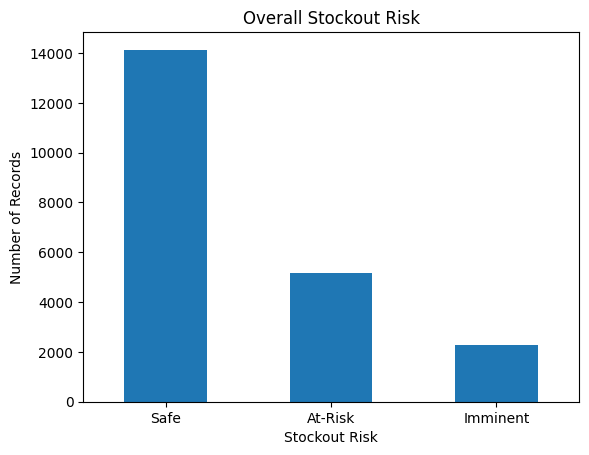

In [ ]:
import matplotlib.pyplot as plt

risk_counts = df['stockout_risk'].value_counts()

risk_counts.plot(kind='bar')
plt.title('Overall Stockout Risk')
plt.xlabel('Stockout Risk')
plt.ylabel('Number of Records')
plt.xticks(rotation=0)
plt.show()

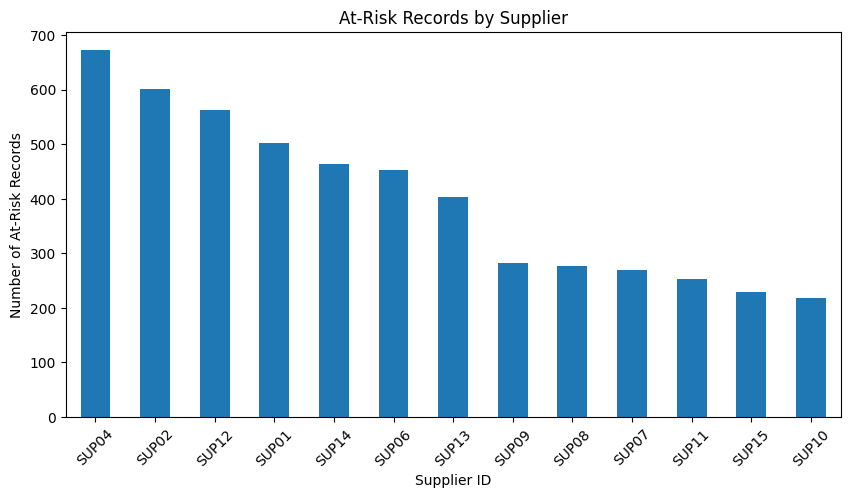

In [ ]:
# Supplier-wise Stockout Risk

supplier_risk['At-Risk'].sort_values(ascending=False).plot(
    kind='bar',
    figsize=(10,5),
    title='At-Risk Records by Supplier'
)

plt.xlabel('Supplier ID')
plt.ylabel('Number of At-Risk Records')
plt.xticks(rotation=45)
plt.show()

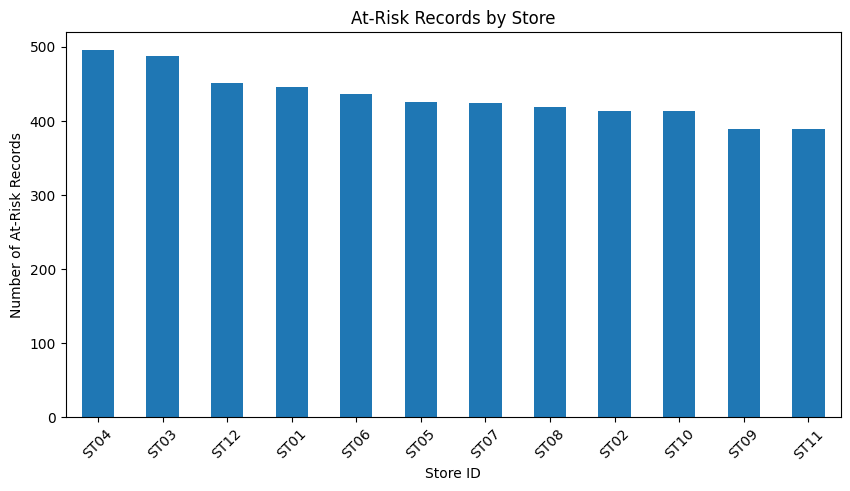

In [ ]:
# Store-wise Stockout Risk

store_risk['At-Risk'].sort_values(ascending=False).plot(
    kind='bar',
    figsize=(10,5),
    title='At-Risk Records by Store'
)

plt.xlabel('Store ID')
plt.ylabel('Number of At-Risk Records')
plt.xticks(rotation=45)
plt.show()

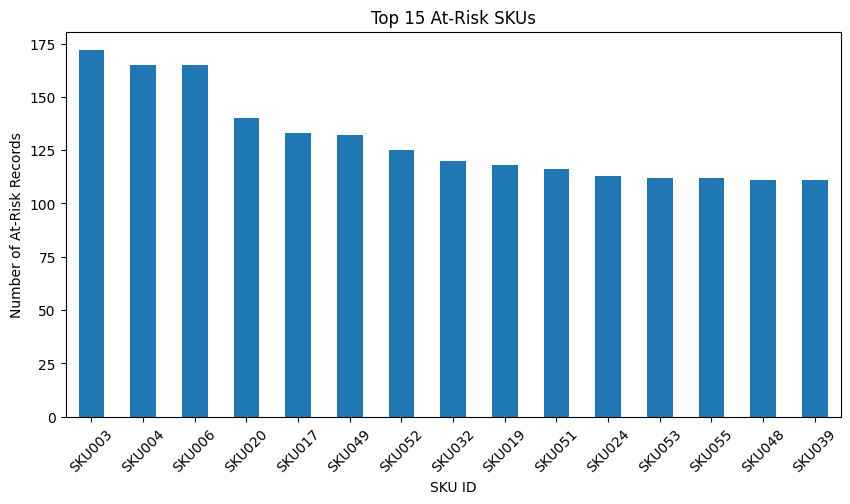

In [ ]:
# SKU-wise Stockout Risk

sku_risk['At-Risk'].sort_values(ascending=False).head(15).plot(
    kind='bar',
    figsize=(10,5),
    title='Top 15 At-Risk SKUs'
)

plt.xlabel('SKU ID')
plt.ylabel('Number of At-Risk Records')
plt.xticks(rotation=45)
plt.show()

In [ ]:
# Top 5 suppliers with highest At-Risk records

top_suppliers = supplier_risk['At-Risk'].sort_values(ascending=False).head(5)

top_suppliers

,At-Risk
supplier_id,
SUP04,672
SUP02,601
SUP12,562
SUP01,502
SUP14,464


In [ ]:
# Overall Stockout Risk Summary

risk_summary = df['stockout_risk'].value_counts()

risk_summary

,count
stockout_risk,
Safe,14131
At-Risk,5186
Imminent,2283


In [ ]:
print("===== FINAL PROJECT INSIGHTS =====")

print("\n1. Overall Stockout Risk:")
print(df['stockout_risk'].value_counts())

print("\n2. Top 5 Risky Suppliers:")
print(df[df['stockout_risk'] == 'At-Risk']['supplier_id'].value_counts().head(5))

print("\n3. Top 5 Risky Stores:")
print(df[df['stockout_risk'] == 'At-Risk']['store_id'].value_counts().head(5))

print("\n4. Top 5 Risky SKUs:")
print(df[df['stockout_risk'] == 'At-Risk']['sku_id'].value_counts().head(5))

===== FINAL PROJECT INSIGHTS =====

1. Overall Stockout Risk:
stockout_risk
Safe        14131
At-Risk      5186
Imminent     2283
Name: count, dtype: int64

2. Top 5 Risky Suppliers:
supplier_id
SUP04    672
SUP02    601
SUP12    562
SUP01    502
SUP14    464
Name: count, dtype: int64

3. Top 5 Risky Stores:
store_id
ST04    495
ST03    487
ST12    451
ST01    446
ST06    436
Name: count, dtype: int64

4. Top 5 Risky SKUs:
sku_id
SKU003    172
SKU004    165
SKU006    165
SKU020    140
SKU017    133
Name: count, dtype: int64


In [ ]:
# FINAL PROJECT INSIGHTS

total = len(df)

safe = (df['stockout_risk'] == 'Safe').sum()
at_risk = (df['stockout_risk'] == 'At-Risk').sum()
imminent = (df['stockout_risk'] == 'Imminent').sum()

print("===== QUICKCART INVENTORY STOCKOUT RISK ANALYSIS =====")

print(f"\nTotal Records: {total}")

print("\nStockout Risk Distribution:")
print(f"Safe      : {safe} ({safe/total*100:.2f}%)")
print(f"At-Risk   : {at_risk} ({at_risk/total*100:.2f}%)")
print(f"Imminent  : {imminent} ({imminent/total*100:.2f}%)")

print("\nTop 5 Risky Suppliers:")
print(df[df['stockout_risk'] == 'At-Risk']['supplier_id'].value_counts().head(5))

print("\nTop 5 Risky Stores:")
print(df[df['stockout_risk'] == 'At-Risk']['store_id'].value_counts().head(5))

print("\nTop 5 Risky SKUs:")
print(df[df['stockout_risk'] == 'At-Risk']['sku_id'].value_counts().head(5))

===== QUICKCART INVENTORY STOCKOUT RISK ANALYSIS =====

Total Records: 21600

Stockout Risk Distribution:
Safe      : 14131 (65.42%)
At-Risk   : 5186 (24.01%)
Imminent  : 2283 (10.57%)

Top 5 Risky Suppliers:
supplier_id
SUP04    672
SUP02    601
SUP12    562
SUP01    502
SUP14    464
Name: count, dtype: int64

Top 5 Risky Stores:
store_id
ST04    495
ST03    487
ST12    451
ST01    446
ST06    436
Name: count, dtype: int64

Top 5 Risky SKUs:
sku_id
SKU003    172
SKU004    165
SKU006    165
SKU020    140
SKU017    133
Name: count, dtype: int64


# QuickCart Warehouse Inventory Stockout Risk Analysis

## 1. Project Overview

This project analyzes warehouse inventory data to identify products, stores, and suppliers that are at risk of stockouts. The analysis uses daily inventory records and stockout risk classifications to support better inventory planning and replenishment decisions.

## 2. Dataset

The main inventory dataset contains **21,600 records** with information about:

- Date
- Store
- SKU
- Supplier
- Opening stock
- Units demanded
- Units sold
- Closing stock
- Reorder point
- Reorder status
- Lead time
- Sales velocity
- Days of cover
- Festival week indicator
- Stockout risk

## 3. Overall Stockout Risk

The analysis identified three risk categories:

| Risk Category | Records | Percentage |
|---|---:|---:|
| Safe | 14,131 | 65.42% |
| At-Risk | 5,186 | 24.01% |
| Imminent | 2,283 | 10.57% |
| **Total** | **21,600** | **100%** |

The majority of inventory records are safe. However, around **34.58%** of records are either **At-Risk or Imminent**, showing a significant need for proactive inventory management.

## 4. Supplier Risk Analysis

The supplier analysis identified the suppliers with the highest number of At-Risk inventory records.

Top risky suppliers:

1. SUP04 – 672
2. SUP02 – 601
3. SUP12 – 562
4. SUP01 – 502
5. SUP14 – 464

These suppliers should be monitored closely because higher-risk inventory records may indicate replenishment or lead-time challenges.

## 5. Store Risk Analysis

The stores with the highest number of At-Risk records are:

1. STO4 – 495
2. STO3 – 487
3. STO12 – 451
4. STO1 – 446
5. STO6 – 436

These stores require closer inventory monitoring and timely replenishment to reduce the possibility of stockouts.

## 6. SKU Risk Analysis

The SKU analysis identified several products with a high number of At-Risk records. The leading SKUs include:

- SKU003
- SKU004
- SKU006
- SKU020
- SKU017

These products should be prioritized for inventory review and replenishment planning.

## 7. Key Insights

- **65.42%** of inventory records are classified as Safe.
- **24.01%** are At-Risk and require monitoring.
- **10.57%** are classified as Imminent, indicating a more urgent stockout concern.
- Supplier **SUP04** has the highest number of At-Risk records.
- Store **STO4** has the highest number of At-Risk records.
- A small group of SKUs contributes significantly to inventory risk.
- Inventory teams can use stockout risk, days of cover, sales velocity, reorder points, and supplier lead times to prioritize replenishment.

## 8. Business Recommendations

1. Prioritize **Imminent** inventory records for immediate action.
2. Monitor the top-risk suppliers and review their lead times.
3. Maintain higher safety stock for high-demand or high-risk SKUs.
4. Closely monitor stores with consistently high At-Risk records.
5. Use sales velocity and days of cover for proactive replenishment.
6. Review supplier performance regularly to reduce supply-related stockout risk.
7. Use festival/event periods to plan additional inventory when demand is expected to increase.

## 9. Conclusion

The QuickCart inventory analysis provides a clear view of stockout risk across products, stores, and suppliers. The results show that although most inventory records are safe, a substantial portion requires attention. By prioritizing imminent risks, monitoring high-risk suppliers and stores, and improving replenishment planning, QuickCart can reduce stockout risk and improve inventory availability.